# Встреча 1. Стоит ли тестировать

**Легенда.** Команда сделала новую страницу чекаута. Владелец продукта спрашивает: «Тестируем или раскатываем сразу? И если тестируем, то сколько и с каким порогом?» Сплит уже решён: на новый чекаут пойдёт 20% трафика. От нас — вердикт с числами: $\alpha$, размер выборки, длительность и решение «тестируем / нет».

Лекция опирается на 11-ю главу книги Georgiev G.Z. *Statistical Methods in Online A/B Testing*. Традиционный подход ($\alpha = 0.05$, $\beta = 0.2$, произвольный минимальный интересующий эффект) игнорирует структуру затрат и выгод конкретного теста. Мы построим модель, которая подбирает $\alpha$ и $n$ под финансовый результат, и посмотрим, что она даёт и где её можно обмануть.

**Разделы**

1. Что считать успехом эксперимента в бизнесе; затраты и выгоды.
2. Параметры теста и распределение ожидаемых эффектов.
3. Точка безубыточности.
4. Затраты и выгоды с поправкой на риск, вероятность внедрения.
5. Отношение выгоды к риску и чистая прибыль.
6. Поиск оптимальных α и n.
7. α = 0.5 — не монетка.
8. Вердикт для кейса.
9. Ограничения модели.

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

### Библиотеки и общие параметры

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm

try:  # слайдеры необязательны: без ipywidgets ноутбук исполняется целиком
    from ipywidgets import FloatSlider, IntSlider, interact
except ImportError:
    interact = None

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/checkout_ab.csv')


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

Кейс — сквозной для воркшопа: интернет-магазин тестирует новую страницу чекаута (данные — `../data/checkout_ab.csv`). Важно не только понять, есть ли эффект, но и оценить, оправданы ли тест и внедрение с точки зрения бизнеса.

Параметры кейса:

* базовая конверсия чекаута в заказ: 70%;
* до чекаута доходит 7 500 пользователей в день, 52 500 в неделю;
* сплит 80/20: новый вариант получает 20% трафика;
* недельная выручка: 137 млн ₽ — средняя выручка пользователя группы A (≈2 605 ₽) × 52 500;
* затраты на тест (вторая версия, QA, аналитика): 3 млн ₽;
* внедрение на 100% трафика (интеграции с платёжками, нагрузка): 10 млн ₽;
* откат на старый чекаут: 5 млн ₽;
* поддержка нового чекаута: 1 млн ₽ в месяц, пока он работает;
* мониторинг после внедрения: 4 недели, за которые без контрольной группы видно падение на 1.5% и больше;
* горизонт планирования: 12 месяцев от старта теста.

Считаем, что относительный рост конверсии даёт такой же относительный рост выручки.

In [2]:
@dataclass
class BusinessCase:
    """Параметры кейса «новый чекаут». Суммы в рублях, эффекты — относительные."""
    baseline_cr: float = 0.70              # конверсия чекаута в группе A
    daily_users: int = 7_500               # пользователей в день доходят до чекаута
    share_b: float = 0.20                  # доля трафика на новый вариант
    weekly_revenue: float = 137_000_000    # ARPU группы A ≈ 2 605 ₽ × 52 500 пользователей в неделю
    fixed_test_cost: float = 3_000_000     # подготовка и проведение теста
    implementation_cost: float = 10_000_000  # раскатка на 100% трафика
    rollback_cost: float = 5_000_000       # откат на старый чекаут
    monthly_maintenance: float = 1_000_000   # поддержка нового чекаута, пока он работает
    horizon_months: float = 12             # горизонт от старта теста
    monitoring_weeks: float = 4            # сколько недель после раскатки смотрим на дашборд
    rollback_threshold: float = -0.015     # падение, которое дашборд замечает без контроля

    @property
    def weekly_users(self) -> float:
        return self.daily_users * 7

    @property
    def horizon_weeks(self) -> float:
        return self.horizon_months * 52 / 12

    @property
    def weekly_maintenance(self) -> float:
        return self.monthly_maintenance * 12 / 52

    @property
    def maintenance_cost(self) -> float:
        return self.monthly_maintenance * self.horizon_months

    @property
    def break_even(self) -> float:
        """Эффект, при котором выручка за горизонт покрывает тест, внедрение и поддержку."""
        costs = self.fixed_test_cost + self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    @property
    def break_even_sunk(self) -> float:
        """Та же точка без затрат на тест: к моменту решения они уже потрачены."""
        costs = self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    def test_weeks(self, n_b):
        """Длительность теста: группа B набирает n_b пользователей при доле share_b."""
        return np.asarray(n_b, dtype=float) / (self.share_b * self.weekly_users)


case = BusinessCase()

Выручку и трафик берём из данных, а не задаём руками:

In [3]:
df = pd.read_csv(DATA)
users = df.drop_duplicates('user_id')            # дубли и «двойные» пользователи — тема встречи 3, здесь они почти не влияют
daily_users = users['user_id'].nunique() / users['date'].nunique()
arpu_a = users.loc[users['group'] == 'A', 'revenue'].mean()
weekly_revenue = round(arpu_a * 7_500 * 7, -6)

print(f"Пользователей в день: {daily_users:,.0f}".replace(',', ' '))
print(f"Доля B: {(users['group'] == 'B').mean():.3f}; конверсия A: {users.loc[users['group'] == 'A', 'converted'].mean():.3f}")
print(f"ARPU группы A: {arpu_a:,.0f} ₽".replace(',', ' '))
print(f"Выручка за неделю: {spaced(arpu_a * 7_500 * 7)} ₽, округлённо {spaced(weekly_revenue)} ₽")
assert weekly_revenue == BusinessCase().weekly_revenue

Пользователей в день: 7 501
Доля B: 0.201; конверсия A: 0.699
ARPU группы A: 2 605 ₽
Выручка за неделю: 136 739 779 ₽, округлённо 137 000 000 ₽


## Определение «успеха» для бизнес-эксперимента

В науке любой корректно проведённый эксперимент полезен, потому что увеличивает знание. В бизнесе критерий иной.

**Ключевой вопрос перед тестом:**
> «Основываясь на наших ограниченных ресурсах, какое действие следует предпринять, чтобы улучшить KPI наиболее экономически эффективным и устойчивым способом?»

**ROI-оптимальный тест** — это тест, дизайн которого максимизирует ожидаемую отдачу. Отдельный такой тест может закончиться и потерями, но в среднем по многим решениям такой дизайн выгоднее других.

Перед существенными действиями нужно ответить на три вопроса с учётом всех рисков:

* Каков общий доход, на который могут повлиять запланированные действия?
* Каков ожидаемый положительный эффект от этих действий?
* Каковы ожидаемые общие затраты, включая постоянные и связанные с рисками?

Оптимизируя первые два параметра и минимизируя третий, мы приближаемся к оптимальной рентабельности инвестиций:

$$
ROI = \frac{\text{Gain} - \text{Costs}}{\text{Costs}}
$$

$$
\text{Gain} = \text{Effect} \times \text{Impact}
$$

Георгиев в книге называет ROI отношение $\text{Gain} / \text{Costs}$. Мы используем стандартное определение: при нём $ROI = 0$ означает, что выгоды только покрыли затраты.

**Вопрос.** Тест показал рост конверсии на +0.2 п.п., p-value = 0.01. Это успех?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Статистически — да: эффект скорее всего больше нуля. Экономически — не обязательно.

Окупается только эффект выше **точки безубыточности**: он должен покрыть тест, внедрение и поддержку. В нашем кейсе это 0.25 п.п. (посчитаем ниже). Оценка +0.2 п.п. ниже порога: такое внедрение в среднем не вернёт затрат.

Поэтому «значимо» и «стоит внедрять» — разные вопросы, и вся встреча — про второй.

</details>

## Затраты, выгоды, риски и вознаграждения

Чтобы разобраться в затратах и выгодах, рассмотрим временную шкалу типичного теста. Затраты возникают на этапе планирования и разработки, во время самого теста и после внедрения выбранного решения. Выгоды возникают только во время теста и после внедрения.

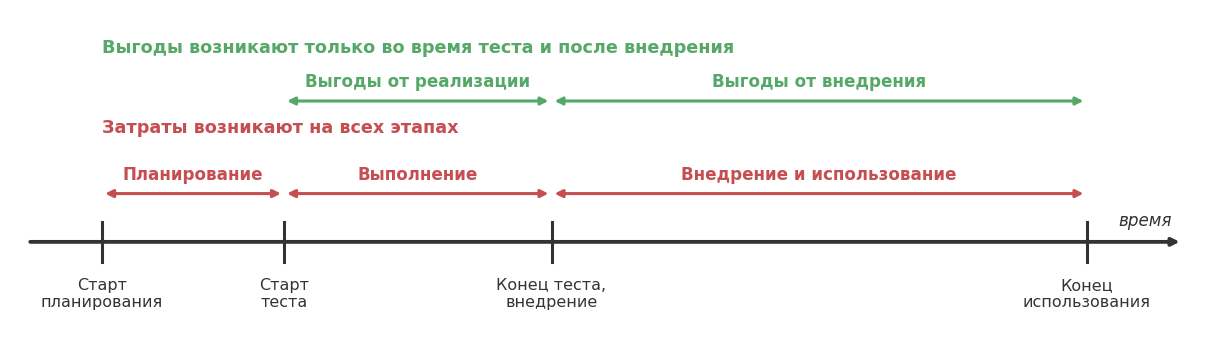

Затраты можно разделить на два типа:

1. **Фиксированные** (единовременные или бессрочные).
2. **Связанные с риском.** Говоря о них в деньгах с учётом вероятности, мы будем называть их **затратами с поправкой на риск** (risk-adjusted).

Выгоды точно так же могут быть связаны с риском, и мы будем говорить о **выгодах с поправкой на риск**. Фиксированных выгод не существует: если выгоду можно получить независимо от результата теста, она с тестом не связана.

«Фиксированные» в «фиксированных затратах» означает, что они возникают с вероятностью $P=1$ независимо от результата теста, но не означает, что их сумма постоянна. Например, подписка на сервис для тестирования наступает с вероятностью 1, но её итоговая сумма зависит от длительности использования.

Отдельно стоит учитывать **стоимость отмены решения**, которое окажется ошибочным.

Тривиальные изменения интерфейса или текста легко и дёшево отменить. Другие решения практически необратимы — например изменения, затрагивающие отношения с партнёрами или крупные инвестиции в инфраструктуру. Для таких решений стоимость ошибки сильно меняет расчёт, а оптимальный порог значимости может стать строже.

## Параметры теста и их связь с затратами и выгодами

Какие параметры теста мы можем менять, чтобы получить оптимальное соотношение риска и выгоды?

Два статистических параметра:

1. порог статистической значимости $\alpha$;
2. размер выборки $n$.

Размер выборки определяет мощность $(1-\beta)$ и минимальный надёжно обнаруживаемый эффект MDE. Он же задаёт длительность теста, потому что поток пользователей ограничен.

Три параметра дизайна:

3. определение нулевой гипотезы (superiority, non-inferiority) и набор метрик;
4. количество вариантов (A/B, A/B/n);
5. схема мониторинга (фиксированный горизонт или последовательный тест).

Нулевая гипотеза, метрики и варианты обычно определяются внешней информацией. Георгиев также считает, что последовательная схема почти всегда выгоднее по ROI (она разбирается на [встрече 4 «Остановка»](<../04. Остановка/README.md>)). Поэтому сосредоточимся на двух параметрах: $n$ и $\alpha$.

Параметры связаны между собой. Меньшая выборка делает тест короче и дешевле, но снижает мощность и повышает риск пропустить хороший вариант. Большая выборка повышает мощность, но откладывает внедрение. Из-за этих компромиссов оптимальные значения приходится искать перебором.

## Распределение ожидаемых эффектов

Истинный эффект $\theta$ заранее неизвестен, поэтому в модели задаётся **распределение ожидаемых эффектов** $\pi(\theta)$. Оно отражает, какие значения эффекта мы считаем более или менее правдоподобными до эксперимента, и обычно строится по истории похожих тестов.

**Важные предостережения:**

1. Это априорное распределение, но сам анализ остаётся частотным: распределение используется только для выбора $\alpha$ и $n$ на этапе дизайна.
2. Равномерное распределение не означает «я ничего не знаю»: это сильное утверждение о том, что все эффекты равновероятны.
3. Есть проблема референтного класса: слишком узкий круг похожих тестов даёт мало данных, а слишком широкий делает оценку неточной для конкретного случая.

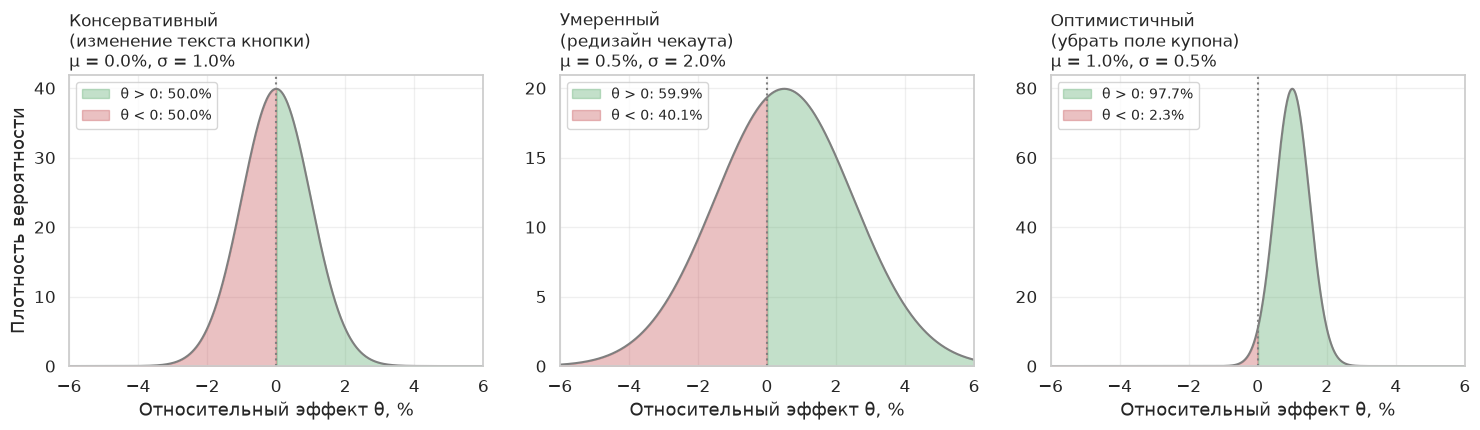

In [4]:
x_eff = np.linspace(-0.06, 0.06, 600)
scenarios = [
    ('Консервативный\n(изменение текста кнопки)', 0.00, 0.01),
    ('Умеренный\n(редизайн чекаута)', 0.005, 0.02),
    ('Оптимистичный\n(убрать поле купона)', 0.01, 0.005),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, loc, scale) in zip(axes, scenarios):
    prior = norm(loc, scale)
    y = prior.pdf(x_eff)
    ax.plot(x_eff * 100, y, color=GRAY, linewidth=1.5)
    ax.fill_between(x_eff * 100, y, where=x_eff >= 0, color=GREEN, alpha=0.35, label=f'θ > 0: {prior.sf(0):.1%}')
    ax.fill_between(x_eff * 100, y, where=x_eff <= 0, color=RED, alpha=0.35, label=f'θ < 0: {prior.cdf(0):.1%}')
    ax.axvline(0, color=GRAY, linestyle=':', linewidth=1.5)
    ax.set_title(f'{title}\nμ = {loc:.1%}, σ = {scale:.1%}', loc='left', fontsize=12)
    ax.set_xlabel('Относительный эффект θ, %')
    ax.set_xlim(-6, 6)
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper left', fontsize=10)
axes[0].set_ylabel('Плотность вероятности')
plt.tight_layout()
plt.show()

| Сценарий | Параметры | P(θ > 0) | Интерпретация |
| :--- | :--- | :---: | :--- |
| **Консервативный** (текст кнопки) | μ = 0%, σ = 1% | 50.0% | Эффект скорее всего близок к нулю и с равной вероятностью будет положительным или отрицательным. |
| **Умеренный** (редизайн чекаута) | μ = 0.5%, σ = 2% | 59.9% | Ожидаем небольшой рост, но разброс велик, и риск ухудшения заметен (около 40%). |
| **Оптимистичный** (убрать поле купона) | μ = 1%, σ = 0.5% | 97.7% | Высокая уверенность в росте, риск ухудшения около 2%. |

Масштаб эффектов здесь меньше, чем в учебниках с конверсией 5%: чекаут уже конвертирует 70%, и до потолка всего 30 п.п. Относительный эффект +1% — это +0.7 п.п.

Выбор распределения сильно влияет на оценку рисков, поэтому ниже мы отдельно проверим чувствительность результата к нему.

**Ожидания в нашем кейсе:** $\theta$ распределено нормально со средним 0 и $\sigma = 1.5$%. Почему так:

* правки страницы чекаута обычно двигают конверсию на доли процентного пункта; $\sigma = 1.5$% значит, что 95% эффектов лежат в пределах ±3%, то есть ±2 п.п., а больше 1 п.п. в любую сторону — треть вариантов;
* среднее 0: новый чекаут с равной вероятностью может оказаться лучше или хуже;
* история тестов (`../data/portfolio_tests.csv`) даёт разброс истинных эффектов ≈3.5% относительных без выброса, но это тесты с базовой конверсией 5%. При базе 70% те же относительные эффекты означали бы правки в 14 раз сильнее в п.п. Это проблема референтного класса: портфель подсказывает порядок, но не число. Расчёт — ниже.

In [5]:
PRIOR_MU, PRIOR_SIGMA = 0.0, 0.015
effect_grid = np.linspace(-0.12, 0.12, 2401)   # одна сетка эффектов на весь ноутбук


def prior_density(mu: float = PRIOR_MU, sigma: float = PRIOR_SIGMA) -> np.ndarray:
    """Нормальное распределение ожиданий на сетке; сетка обрезает хвосты, поэтому нормируем заново."""
    weights = norm.pdf(effect_grid, mu, sigma)
    return weights / np.trapezoid(weights, effect_grid)


density = prior_density()

**Ожидания по истории тестов.** Оценим разброс эффектов по портфелю прошлых тестов `portfolio_tests.csv` (эффект и SE — в п.п. конверсии).

Наблюдаемый эффект теста — это истинный эффект плюс шум: $\hat\theta_i = \theta_i + \varepsilon_i$, где дисперсия шума равна $SE_i^2$. Поэтому разброс наблюдаемых эффектов завышает разброс истинных. Оценка методом моментов:

$$
\hat\tau^2 = \max\left(0, \mathrm{Var}(\hat\theta_i) - \overline{SE_i^2}\right)
$$

Эффекты и SE переводим в относительные (делим на `base_rate`) и считаем оценку по всем тестам и без самого большого эффекта.

In [6]:
portfolio = pd.read_csv('../data/portfolio_tests.csv')
portfolio

,test_id,name,metric,n,base_rate,effect,se,ci_low,ci_high,p_value
0,HD-101,Блок рекомендаций на главной,"конверсия, п.п.",52000,0.050,0.334,0.135,0.069,0.599,0.0135
1,PRM-104,Промо-баннер в выдаче,"конверсия, п.п.",38000,0.048,0.276,0.155,-0.028,0.580,0.0751
2,CHK-203,Новый чекаут v2,"конверсия, п.п.",78000,0.052,0.187,0.112,-0.033,0.408,0.0954
3,PUSH-307,Другое время push-рассылки,"конверсия, п.п.",64000,0.050,0.063,0.122,-0.176,0.302,0.6064
4,ONB-112,Мобильный онбординг,"конверсия, п.п.",30000,0.047,1.210,0.173,0.871,1.549,0.0000
5,FILT-408,Фильтр по цене в поиске,"конверсия, п.п.",44000,0.051,-0.227,0.148,-0.518,0.064,0.1257


In [7]:
relative = portfolio['effect'] / 100 / portfolio['base_rate']
relative_se = portfolio['se'] / 100 / portfolio['base_rate']


def tau(effects, ses) -> float:
    return float(np.sqrt(max(0.0, effects.var(ddof=1) - (ses ** 2).mean())))


keep = relative < relative.max()
tau_all = tau(relative, relative_se)
tau_wo_outlier = tau(relative[keep], relative_se[keep])
print(f"Наблюдаемый разброс: {relative.std(ddof=1):.1%}; средний шум SE: {np.sqrt((relative_se ** 2).mean()):.1%}")
print(f"τ по всем тестам: {tau_all:.1%}; без выброса: {tau_wo_outlier:.1%}")

Наблюдаемый разброс: 10.3%; средний шум SE: 2.9%
τ по всем тестам: 9.8%; без выброса: 3.5%


**Вопрос.** Можно ли просто взять $\sigma = 3.5$% для нашего чекаута?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет, и тут сразу три проблемы.

1. **Референтный класс.** В портфеле базовая конверсия ~5%, у нас — 70%. Относительный эффект +3.5% при базе 5% — это +0.18 п.п., при базе 70% — +2.5 п.п. Это совсем другая по силе правка. Перенос в относительных величинах завышает $\sigma$, в абсолютных — занижает.
2. **Шум и малое число тестов.** По шести тестам дисперсия оценивается очень грубо, а вычитание $\overline{SE^2}$ легко даёт ноль или отрицательное число.
3. **Выброс.** Один онбординг (+26%) утраивает оценку. Выбрасывать его тоже нельзя без причины: тяжёлые хвосты эффектов — реальность, и нормальное распределение их недооценивает.

Поэтому $\sigma$ — это суждение, подкреплённое историей, и его обязательно проверяют на чувствительность (раздел «Поиск оптимальных α и n»). Сжатие оценок отдельных тестов к общему среднему (shrinkage) и мета-анализ портфеля — встреча 6.

</details>

## Расчёт отношения выгоды к риску

### Точка безубыточности

Первый шаг к расчёту ROI — определить **точку безубыточности по фиксированным затратам (fixed-cost break-even point)**. Обычно это очень небольшой относительный прирост, часто ниже 1%, потому что затраты на большинство тестов невелики по сравнению с их влиянием за время использования.

В точке безубыточности выгода равна затратам, то есть $ROI = 0$:

$$
\text{break-even effect} \times \text{Revenue} = \text{Fixed Costs}
$$

$$
\text{break-even effect} = \frac{\text{Fixed Costs}}{\text{Revenue}}
$$

Выручка — это выручка за неделю $W$, умноженная на горизонт $H$ в неделях. В обозначениях кейса:

$$
\theta_{BE} = \frac{C_{test} + C_{impl} + C_{maint}}{W \cdot H}
$$

Здесь в затраты входят тест, внедрение и поддержка за весь горизонт: мы считаем, сколько должен принести запущенный вариант, чтобы вся затея окупилась. К моменту решения деньги на тест уже потрачены (sunk cost), и для самого решения их можно не учитывать; что от этого меняется, проверим ниже. Точка равна нулю только в редком случае, когда побочные эффекты изменения в точности компенсируют эти затраты.

Точка безубыточности определяет, что такое успех: улучшение метрики само по себе ничего не говорит о затратах на его внедрение и поддержку. Поэтому и тест мы будем строить вокруг неё.

Суммарные фиксированные издержки: 25 000 000 ₽
Точка безубыточности по фиксированным затратам: 0.351% относительных = 0.25 п.п.
Без затрат на тест: 0.309%


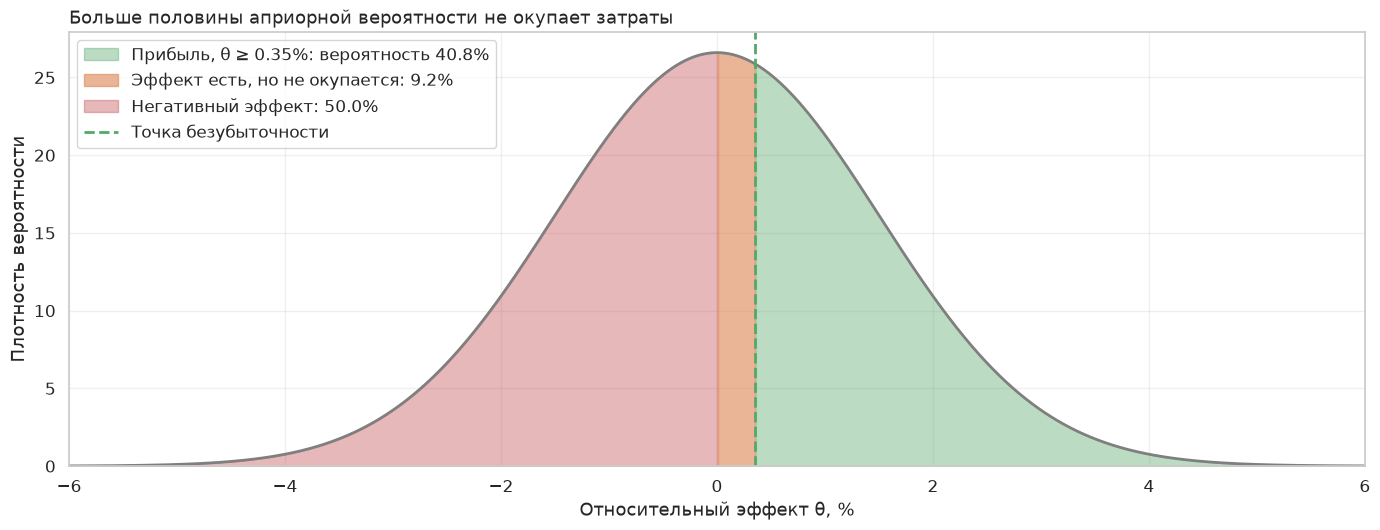

In [8]:
fixed_costs = case.fixed_test_cost + case.implementation_cost + case.maintenance_cost
break_even = case.break_even
print(f"Суммарные фиксированные издержки: {spaced(fixed_costs)} ₽")
print(f"Точка безубыточности по фиксированным затратам: {break_even:.3%} относительных = {break_even * case.baseline_cr * 100:.2f} п.п.")
print(f"Без затрат на тест: {case.break_even_sunk:.3%}")

prior = norm(PRIOR_MU, PRIOR_SIGMA)
x = effect_grid * 100

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(x, density, color=GRAY, linewidth=2)
ax.fill_between(x, density, where=effect_grid >= break_even, color=GREEN, alpha=0.4,
                label=f'Прибыль, θ ≥ {break_even:.2%}: вероятность {prior.sf(break_even):.1%}')
ax.fill_between(x, density, where=(effect_grid > 0) & (effect_grid < break_even), color=ORANGE, alpha=0.6,
                label=f'Эффект есть, но не окупается: {prior.cdf(break_even) - prior.cdf(0):.1%}')
ax.fill_between(x, density, where=effect_grid <= 0, color=RED, alpha=0.4, label=f'Негативный эффект: {prior.cdf(0):.1%}')
ax.axvline(break_even * 100, color=GREEN, linestyle='--', linewidth=2, label='Точка безубыточности')
ax.set_title('Больше половины априорной вероятности не окупает затраты', loc='left')
ax.set_xlabel('Относительный эффект θ, %')
ax.set_ylabel('Плотность вероятности')
ax.set_xlim(-6, 6)
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Значения левее точки безубыточности не окупаются даже при положительном uplift. Точка мала — 0.35%, или 0.25 п.п.: затраты (25 млн ₽) малы против выручки за год (7.1 млрд ₽). Тем не менее около 9% вариантов попадают в зону «эффект есть, но не окупается».

Расчёты ниже предполагают биномиальную метрику, конверсию покупок, но аналогично работают и для непрерывных показателей вроде ARPU.

### Затраты и выгоды с поправкой на риск

Для расчёта нужны:

* затраты, которые мы несём независимо от результата: $C_{test}$;
* затраты, которые появляются только при внедрении: внедрение $C_{impl}$, поддержка $m$ в неделю, пока вариант работает, и откат $C_{rb}$, если он случился;
* базовая конверсия, трафик $U = 52500$ пользователей в неделю и доля $s = 0.2$ варианта B;
* выручка за неделю $W$ и горизонт $H$ недель.

Тест длится $T = n_B / (s \cdot U)$ недель: длительность задаёт меньшая группа. Во время теста вариант видят 20% пользователей, поэтому затронутая выручка — $s \cdot W \cdot T$.

**Что происходит после внедрения.** Первые $L = 4$ недели смотрим на дашборд. Контрольной группы уже нет, поэтому видно только крупное падение: $\theta < \theta_{RB}$, где $\theta_{RB} = -1.5$% (≈1 п.п.).

Такой вариант откатываем: он работал $L$ недель, и мы платим потери за эти недели, поддержку и $C_{rb}$.

Все остальные варианты работают до конца горизонта. Среди них и слабо вредные (от −1.5% до 0), и «есть, но не окупаются» (от 0 до $\theta_{BE}$). Обозначим $\ell(\theta)$ число недель работы варианта после внедрения:

* $\ell(\theta) = L$, если $\theta < \theta_{RB}$ (откат);
* $\ell(\theta) = H - T$ в остальных случаях.

Правило согласовано: откат обрывает и потери, и выгоду; без отката потери и выгода идут весь остаток горизонта. Каждая неделя теста откладывает внедрение и сокращает $\ell$ — это и делает слишком длинные тесты невыгодными.

**Затраты с поправкой на риск** получаем интегрированием по распределению ожиданий:

$$
Cost_{RA} = C_{test} + \int_a^b f_c(\theta) d\theta
$$

$$
f_c(\theta) = \pi(\theta) \cdot \left( c_{test}(\theta) + POW(\alpha; \theta) \cdot c_{post}(\theta) \right)
$$

Здесь:

* $c_{test}(\theta) = \max(-\theta \cdot s \cdot W \cdot T, 0)$ — потери во время теста;
* $c_{post}(\theta) = \max(-\theta \cdot W \ell(\theta), 0) + C_{impl} + m \cdot \ell(\theta)$ — потери и затраты после внедрения; при откате к ним добавляется $C_{rb}$;
* $POW(\alpha; \theta)$ — вероятность внедрения при истинном эффекте $\theta$;
* $a$ и $b$ — пределы сетки эффектов.

**Выгоды с поправкой на риск** считаются так же; разовой выгоды от внедрения в нашем кейсе нет:

$$
Gain_{RA} = \int_a^b f_g(\theta) d\theta
$$

$$
f_g(\theta) = \pi(\theta) \cdot \left( g_{test}(\theta) + POW(\alpha; \theta) \cdot g_{post}(\theta) \right)
$$

где $g_{test}(\theta) = \max(\theta \cdot s \cdot W \cdot T, 0)$ и $g_{post}(\theta) = \max(\theta \cdot W \ell(\theta), 0)$.

**Вопрос.** Какой внедрённый вариант обойдётся дороже: хуже контроля на 3% или на 1%?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Вариант на −1%, хотя он «менее плохой».

* **−3%** ниже порога отката: дашборд его заметит, через 4 недели откатим. Потери выручки — около 137 млн × 3% × 4 ≈ 16 млн ₽ плюс 5 млн ₽ на откат.
* **−1%** мониторинг без контрольной группы не видит. Вариант работает весь остаток горизонта, около 50 недель: 137 млн × 1% × 50 ≈ 68 млн ₽.

Крупный вред страхует откат, а мелкий вред отсекает только тест. Поэтому модель так ценит выборку: она нужна, чтобы не пропустить слабо вредные варианты.

</details>

#### Вероятность внедрения

В этом фреймворке решение о внедрении связывается не с проверкой нулевого эффекта, а с проверкой того, превышает ли эффект **точку безубыточности**. Рассмотрим одностороннюю гипотезу:

$$
H_0: \theta \le \theta_{BE} \qquad H_1: \theta > \theta_{BE}
$$

Новый вариант достоин внедрения, только если есть статистические основания считать, что его эффект выше уровня экономической оправданности.

Пусть $\hat{\delta}$ — оценка абсолютной разницы конверсий, $\delta_{BE} = p_A \theta_{BE}$ — разница, соответствующая точке безубыточности, а $SE$ — стандартная ошибка оценки. При сплите 80/20 контрольная группа вчетверо больше: $n_A = n_B (1 - s) / s$. Стандартная ошибка:

$$
SE = \sqrt{\frac{p_A(1-p_A)}{n_A} + \frac{p_B(1-p_B)}{n_B}}
$$

Решение о внедрении принимается, если

$$
\frac{\hat{\delta} - \delta_{BE}}{SE} > z_{1-\alpha}
$$

то есть если

$$
\hat{\delta} > \delta_{BE} + z_{1-\alpha} \cdot SE
$$

Обратите внимание: здесь $\alpha$ **односторонний** и равен вероятности внедрения при $\theta = \theta_{BE}$. Привычный двусторонний уровень 0.05 соответствует одностороннему 0.025.

**Вопрос.** Аналитик по привычке предлагает двусторонний критерий с α = 0.05. Почему здесь односторонний и что изменится, если взять двусторонний?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Решение здесь одностороннее: внедряем, только если B лучше. Значимо худший B и незначимый результат ведут к одному действию — «не внедряем».

Двусторонний критерий тратит половину α на сторону, которая решение не меняет. По сути это односторонний α = 0.025 — порог строже, чем задумано, и хорошие варианты пропускаются чаще.

Двусторонний нужен, когда важно направление в обе стороны: например, если значимое ухудшение само по себе запускает действие (разбор инцидента, откат соседней фичи).

</details>

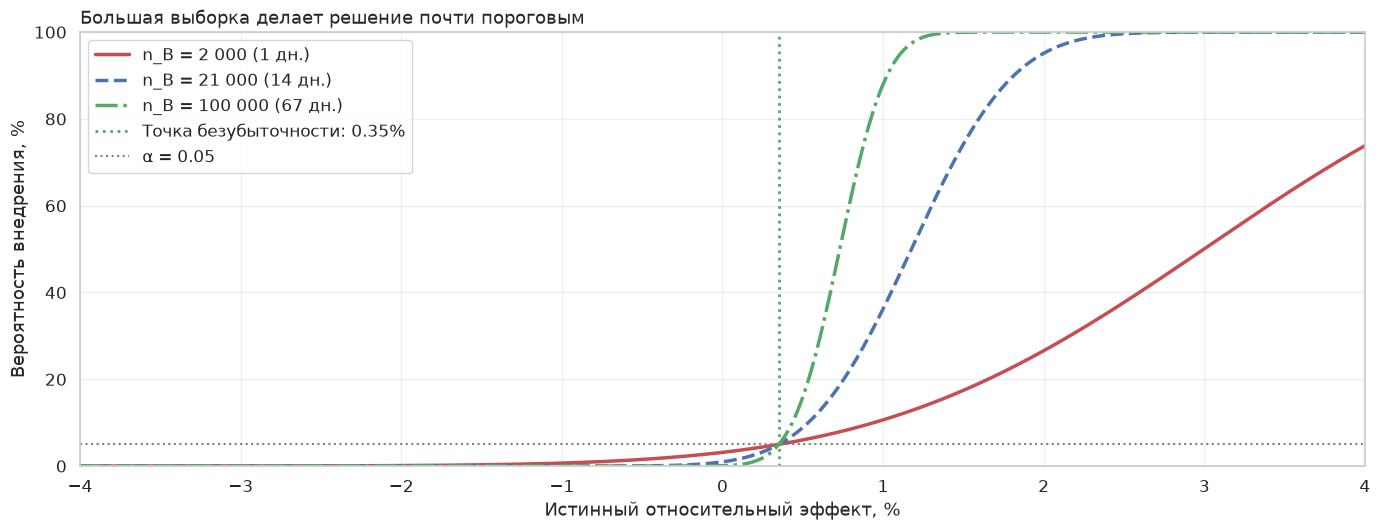

In [9]:
def implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha=0.05, share_b=0.2):
    """Вероятность внедрения: оценка разницы выше порога delta_BE + z_{1-alpha} * SE. Сплит share_b, n_A = n_b (1 - s) / s."""
    n_b = np.asarray(n_b, dtype=float)
    n_a = n_b * (1 - share_b) / share_b
    p_true = np.clip(p_control * (1 + relative_effect), 1e-6, 1 - 1e-6)
    delta_true = p_true - p_control
    delta_be = p_control * break_even_effect
    se = np.sqrt(p_control * (1 - p_control) / n_a + p_true * (1 - p_true) / n_b)
    return norm.sf(norm.ppf(1 - alpha) - (delta_true - delta_be) / se)


fig, ax = plt.subplots(figsize=(14, 5.5))
for n_b, color, style in [(2_000, RED, '-'), (21_000, BLUE, '--'), (100_000, GREEN, '-.')]:
    probability = implementation_probability(case.baseline_cr, effect_grid, break_even, n_b, 0.05, case.share_b)
    ax.plot(effect_grid * 100, probability * 100, color=color, linestyle=style, linewidth=2.5,
            label=f'n_B = {spaced(n_b)} ({case.test_weeks(n_b) * 7:.0f} дн.)')
ax.axvline(break_even * 100, color=GREEN, linestyle=':', linewidth=2, label=f'Точка безубыточности: {break_even:.2%}')
ax.axhline(5, color=GRAY, linestyle=':', linewidth=1.5, label='α = 0.05')
ax.set_title('Большая выборка делает решение почти пороговым', loc='left')
ax.set_xlabel('Истинный относительный эффект, %')
ax.set_ylabel('Вероятность внедрения, %')
ax.set_xlim(-4, 4)
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Чем больше выборка, тем выше вероятность внедрения для эффектов выше точки безубыточности и тем ниже она для эффектов ниже этой точки. Все кривые проходят через одну точку: при $\theta = \theta_{BE}$ вероятность внедрения равна $\alpha$ при любом $n$.

**Вопрос.** Что меняется, если отдать B не 20%, а 50% трафика при той же длительности?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

При том же общем трафике $N$ группа B растёт с $0.2N$ до $0.5N$, а контрольная группа падает с $0.8N$ до $0.5N$. Дисперсия разницы пропорциональна $1/n_A + 1/n_B$: это $6.25/N$ для 80/20 и $4/N$ для 50/50.

Итог: кривые станут круче, как при выборке в 1.56 раза больше. Цена — сырой вариант видит больше пользователей, и если он плох, во время теста теряем больше денег.

</details>

**Вопрос.** Точка безубыточности — 0.25 п.п. Это много или мало для теста на две недели? Сколько это заказов в неделю?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Мало. За две недели группа B набирает 21 000 пользователей, A — 84 000.

Стандартная ошибка разницы конверсий — $\sqrt{0.21/84000 + 0.21/21000} \approx 0.35$ п.п. Это больше самой точки безубыточности.

Значит, тест не отличит надёжно «чуть выше BE» от «чуть ниже». Это нормально: его задача — отсечь заметно худшие варианты и пропустить заметно лучшие.

В заказах: 0.25 п.п. от 52 500 пользователей в неделю — около 130 дополнительных заказов. В деньгах — 0.48 млн ₽ выручки в неделю (0.35% от 137 млн). За 52 недели набегает ровно 25 млн ₽ — столько стоят тест, внедрение и год поддержки.

</details>

### Отношение выгоды к риску

Определим отношение выгоды к риску:

$$
RR = \frac{Gain_{RA}}{Cost_{RA}}
$$

Значение $RR > 1$ означает, что ожидаемая выгода превышает ожидаемые затраты, а $ROI = RR - 1$. Георгиев и многие инструменты используют обратное отношение (risk/reward, например 1/4), где чем меньше, тем лучше. Мы будем смотреть на вариант, где чем больше, тем лучше.

Вместе с отношением будем считать **ожидаемую чистую прибыль**: $Net = Gain_{RA} - Cost_{RA}$. Отношение и прибыль отвечают на разные вопросы, и ниже мы увидим, что они выбирают разные дизайны.

**Оговорка про RR.** Прибыль не зависит от того, в какую колонку записать статью, а отношение — зависит. Если провести внедрение не как затрату, а как минус в выгодах, $Net$ останется прежним, а $RR$ и его оптимум сдвинутся (посчитаем ниже). Поэтому $RR$ — не свойство дизайна, а свойство бухгалтерии.

#### Реализация

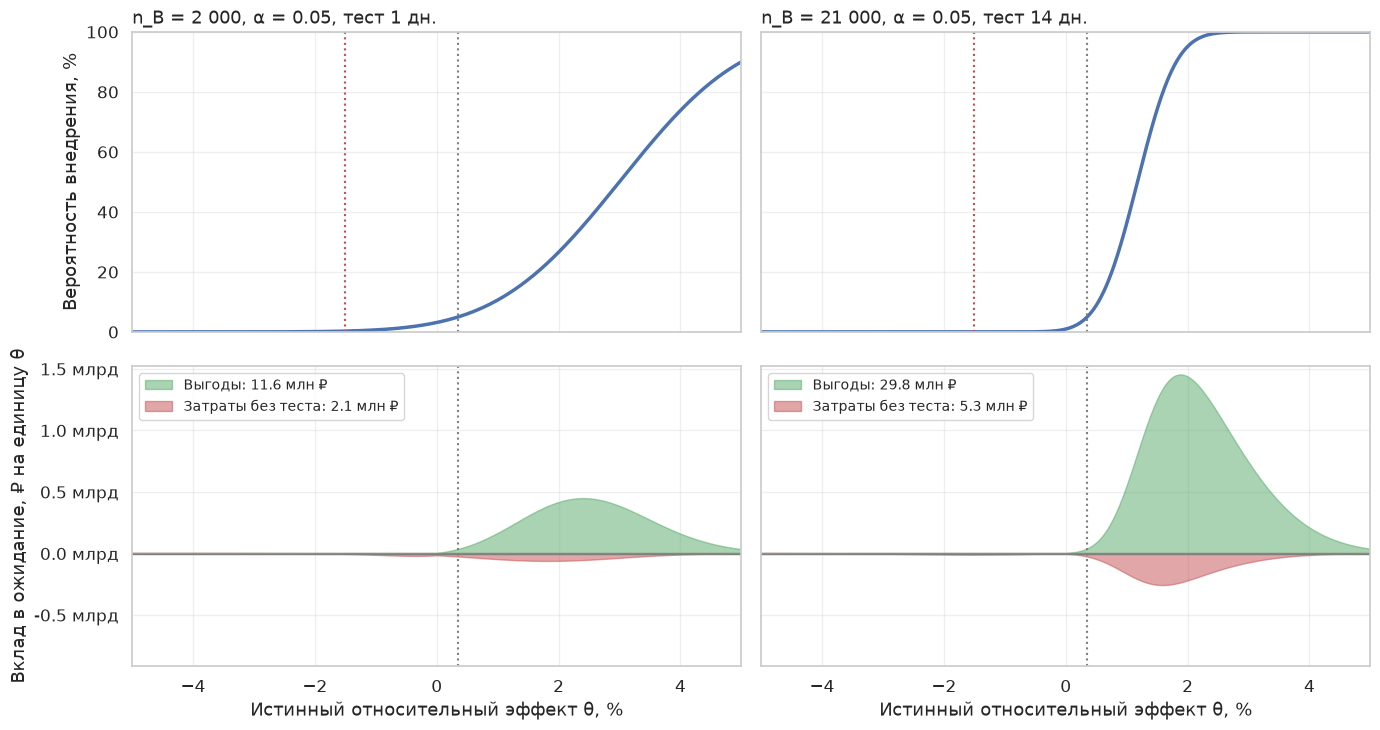

,n_B = 2 000,n_B = 21 000
"Выгоды, млн ₽",11.61,29.83
"Затраты, млн ₽",5.07,8.26
"Чистая прибыль, млн ₽",6.53,21.58
RR,2.29,3.61


In [10]:
def evaluate_design(case, effect_grid, density, n_b, alpha, break_even=None):
    """
    Выгоды и затраты с поправкой на риск для дизайна (n_b, alpha).

    break_even — порог решения (по умолчанию case.break_even; 0 — «стандартная» проверка против нуля).
    n_b и alpha можно передать массивами: ось эффектов всегда последняя.
    """
    threshold = case.break_even if break_even is None else break_even
    probability = implementation_probability(case.baseline_cr, effect_grid, threshold, n_b, alpha, case.share_b)

    test_weeks = case.test_weeks(n_b)
    post_weeks = np.maximum(case.horizon_weeks - test_weeks, 0)   # длинный тест откладывает внедрение
    watch_weeks = np.minimum(case.monitoring_weeks, post_weeks)    # мониторинг после раскатки
    rest_weeks = post_weeks - watch_weeks                          # остаток горизонта
    keep = effect_grid >= case.rollback_threshold                  # падение ниже порога видно и откатывается
    live_weeks = watch_weeks + rest_weeks * keep                   # сколько недель вариант работает

    test_value = case.share_b * case.weekly_revenue * effect_grid * test_weeks   # 20% трафика во время теста
    live_value = case.weekly_revenue * effect_grid * live_weeks
    decision_costs = (case.implementation_cost + case.weekly_maintenance * live_weeks
                      + case.rollback_cost * (~keep))

    gains = (np.maximum(test_value, 0) + np.maximum(live_value, 0) * probability) * density
    losses = (np.maximum(-test_value, 0) + (np.maximum(-live_value, 0) + decision_costs) * probability) * density

    expected_gain = np.trapezoid(gains, effect_grid, axis=-1)
    expected_loss = case.fixed_test_cost + np.trapezoid(losses, effect_grid, axis=-1)
    return {
        'probability': probability,
        'gains': gains,
        'losses': losses,
        'expected_gain': expected_gain,
        'expected_loss': expected_loss,
        'rr': expected_gain / expected_loss,
        'net': expected_gain - expected_loss,
    }


def ship_without_test(case, effect_grid, density):
    """Внедрить сразу: нет затрат на тест и задержки, но мониторинг и откат те же."""
    keep = effect_grid >= case.rollback_threshold
    live_weeks = case.monitoring_weeks + (case.horizon_weeks - case.monitoring_weeks) * keep
    profit = (case.weekly_revenue * effect_grid * live_weeks - case.implementation_cost
              - case.weekly_maintenance * live_weeks - case.rollback_cost * (~keep))
    return np.trapezoid(profit * density, effect_grid)



def describe_design(result: dict) -> pd.Series:
    """Собирает итоговые показатели дизайна."""
    return pd.Series({
        'Выгоды, ₽': result['expected_gain'],
        'Затраты, ₽': result['expected_loss'],
        'Чистая прибыль, ₽': result['net'],
        'RR': result['rr'],
    })


def plot_risk_adjusted(designs: list) -> None:
    """Показывает вероятность внедрения и подынтегральные выгоды и затраты для списка дизайнов (n_B, alpha)."""
    results = [evaluate_design(case, effect_grid, density, n, alpha) for n, alpha in designs]
    limit = max(max(r['gains'].max(), r['losses'].max()) for r in results) * 1.05
    x = effect_grid * 100

    fig, axes = plt.subplots(2, len(designs), figsize=(7 * len(designs), 7.5), sharex=True, sharey='row', squeeze=False)
    for column, ((n, alpha), result) in enumerate(zip(designs, results)):
        top, bottom = axes[0, column], axes[1, column]
        top.plot(x, result['probability'] * 100, color=BLUE, linewidth=2.5)
        top.axvline(break_even * 100, color=GRAY, linestyle=':', linewidth=1.5)
        top.axvline(case.rollback_threshold * 100, color=RED, linestyle=':', linewidth=1.5)
        top.set_ylim(0, 100)
        top.set_title(f'n_B = {spaced(n)}, α = {alpha}, тест {case.test_weeks(n) * 7:.0f} дн.', loc='left')

        bottom.fill_between(x, result['gains'], color=GREEN, alpha=0.5, label=f"Выгоды: {result['expected_gain'] / 1e6:.1f} млн ₽")
        bottom.fill_between(x, -result['losses'], color=RED, alpha=0.5,
                            label=f"Затраты без теста: {(result['expected_loss'] - case.fixed_test_cost) / 1e6:.1f} млн ₽")
        bottom.axhline(0, color=GRAY, linewidth=1)
        bottom.axvline(break_even * 100, color=GRAY, linestyle=':', linewidth=1.5)
        bottom.set_ylim(-0.6 * limit, limit)
        bottom.set_xlabel('Истинный относительный эффект θ, %')
        bottom.legend(loc='upper left', fontsize=10)

    axes[0, 0].set_ylabel('Вероятность внедрения, %')
    axes[1, 0].set_ylabel('Вклад в ожидание, ₽ на единицу θ')
    axes[1, 0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e9:.1f} млрд'))
    plt.xlim(-5, 5)
    plt.tight_layout()
    plt.show()


designs_example = [(2_000, 0.05), (21_000, 0.05)]
plot_risk_adjusted(designs_example)
example = pd.DataFrame({f'n_B = {spaced(n)}': describe_design(evaluate_design(case, effect_grid, density, n, alpha))
                        for n, alpha in designs_example})
example.iloc[:3] /= 1e6
example.rename(index=lambda name: name.replace('₽', 'млн ₽')).round(2)

Как читать графики. Верхний ряд показывает вероятность внедрения; серая линия — точка безубыточности, красная — порог отката −1.5%. Нижний ряд показывает вклад каждого значения $\theta$ в ожидание: он уже взвешен распределением $\pi(\theta)$, поэтому площадь зелёной области равна выгодам, а красной — затратам без 3 млн ₽ на тест. Ступенька красной области на −1.5% — это откат: левее неё потери обрываются через 4 недели.

При $n_B = 2000$ (≈1.3 дня) тест слабый: вероятность внедрения растёт с эффектом медленно, и прибыль всего 6.5 млн ₽ ($RR = 2.29$). При $n_B = 21000$ (2 недели) тот же уровень значимости даёт 21.6 млн ₽ и $RR = 3.61$.

Формулы можно проверить независимо: разыграем тот же процесс целиком. Берём случайный истинный эффект из априорного распределения, генерируем конверсии в группах при сплите 80/20, применяем правило внедрения, откатываем крупные провалы после мониторинга и считаем деньги.

In [11]:
def simulate_design(case: BusinessCase, n_b: int, alpha: float, break_even: float = None,
                    n_sims: int = 400_000, seed: int = 42) -> tuple:
    """Оценивает среднюю прибыль дизайна полным разыгрыванием экспериментов."""
    rng = np.random.default_rng(seed)
    threshold = case.break_even if break_even is None else break_even
    theta = rng.normal(PRIOR_MU, PRIOR_SIGMA, n_sims)
    theta = theta[np.abs(theta) <= effect_grid.max()]   # та же область интегрирования, что и в формулах

    n_a = int(round(n_b * (1 - case.share_b) / case.share_b))
    p_control = case.baseline_cr
    control = rng.binomial(n_a, p_control, theta.size) / n_a
    treatment = rng.binomial(n_b, p_control * (1 + theta)) / n_b
    se = np.sqrt(control * (1 - control) / n_a + treatment * (1 - treatment) / n_b)
    ship = (treatment - control - p_control * threshold) / se > norm.ppf(1 - alpha)

    # Деньги по шагам: тест -> (если внедрили) мониторинг -> откат или работа до конца горизонта
    test_weeks = n_b / (case.share_b * case.weekly_users)
    watch = min(case.monitoring_weeks, case.horizon_weeks - test_weeks)
    rest = case.horizon_weeks - test_weeks - watch
    rolled_back = theta < case.rollback_threshold

    profit = case.share_b * case.weekly_revenue * theta * test_weeks - case.fixed_test_cost
    after_ship = np.where(
        rolled_back,
        (case.weekly_revenue * theta - case.weekly_maintenance) * watch - case.rollback_cost,
        (case.weekly_revenue * theta - case.weekly_maintenance) * (watch + rest),
    ) - case.implementation_cost
    profit += ship * after_ship
    return profit.mean(), profit.std() / np.sqrt(theta.size)


for n, alpha in designs_example + [(24_300, 0.5)]:
    formula = evaluate_design(case, effect_grid, density, n, alpha)['net']
    simulated, error = simulate_design(case, n, alpha)
    print(f"n_B = {spaced(n)}, α = {alpha}: формула {spaced(formula)} ₽, симуляция {spaced(simulated)} ± {spaced(1.96 * error)} ₽")
    assert abs(formula - simulated) < 3 * error, 'Формула и симуляция разошлись'

n_B = 2 000, α = 0.05: формула 6 533 824 ₽, симуляция 6 560 962 ± 122 880 ₽


n_B = 21 000, α = 0.05: формула 21 576 881 ₽, симуляция 21 594 703 ± 165 704 ₽


n_B = 24 300, α = 0.5: формула 26 085 565 ₽, симуляция 26 110 646 ± 167 680 ₽


#### Замечания о сложных ситуациях

1. При последовательном мониторинге длительность теста зависит от неизвестного истинного эффекта. Зная распределение ожиданий, можно рассчитать среднюю длительность и использовать её для оценки затронутого дохода.
2. Увеличение числа вариантов вводит дополнительные допущения при расчёте выборки и иногда требует отдельного распределения ожиданий для каждого варианта. Математика усложняется, но логика вычислений остаётся той же.

## Поиск оптимальных α и n

Рассчитаем выгоды и затраты для всех сочетаний $\alpha$ и $n_B$ и сравним дизайны.

У поиска есть две типичные ловушки:

* **Край сетки.** Если оптимум лежит на границе сетки, настоящего оптимума мы не нашли. Поэтому сетка по $n_B$ идёт до 300 тыс., то есть до 200 дней теста.
* **Критерий.** Максимум отношения $RR$ и максимум прибыли $Net$ в общем случае не совпадают, поэтому посмотрим на оба.

In [12]:
alpha_grid = np.array([0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8])
n_grid = np.unique(np.round(np.geomspace(1_000, 300_000, 60), -2)).astype(int)   # n_B: от 0.7 дня до 200 дней


def design_grid(case: BusinessCase, weights: np.ndarray = None, break_even: float = None) -> dict:
    """Считает RR и прибыль для всех сочетаний alpha и n_B."""
    weights = density if weights is None else weights
    return evaluate_design(case, effect_grid, weights, n_grid[None, :, None], alpha_grid[:, None, None], break_even)


def best_design(grid: dict, metric: str) -> tuple:
    """Находит alpha и n_B с максимальным значением метрики."""
    row, column = np.unravel_index(np.argmax(grid[metric]), grid[metric].shape)
    return alpha_grid[row], n_grid[column], grid['rr'][row, column], grid['net'][row, column]


grid = design_grid(case)
results_df = pd.DataFrame([best_design(grid, 'rr'), best_design(grid, 'net')],
                          index=['Максимум RR', 'Максимум прибыли'],
                          columns=['α', 'n_B', 'RR', 'Чистая прибыль, ₽'])
results_df['Длительность, дней'] = (case.test_weeks(results_df['n_B']) * 7).round(1)
results_df['Чистая прибыль, млн ₽'] = results_df.pop('Чистая прибыль, ₽') / 1e6
results_df.round(3)

,α,n_B,RR,"Длительность, дней","Чистая прибыль, млн ₽"
Максимум RR,0.05,18200,3.617,12.1,20.988
Максимум прибыли,0.50,24300,3.092,16.2,26.086


**Стандартный дизайн** считаем честно: двусторонний $\alpha = 0.05$ (односторонний 0.025), мощность 80% на MDE = +1 п.п., сплит 80/20 и решение **против нуля** ($\theta_{BE} = 0$). Такой дизайн выдаёт обычный калькулятор размера выборки: $n_B \approx 20.6$ тыс., 14 дней. Рядом покажем гибрид: тот же $n$, но решение против точки безубыточности.

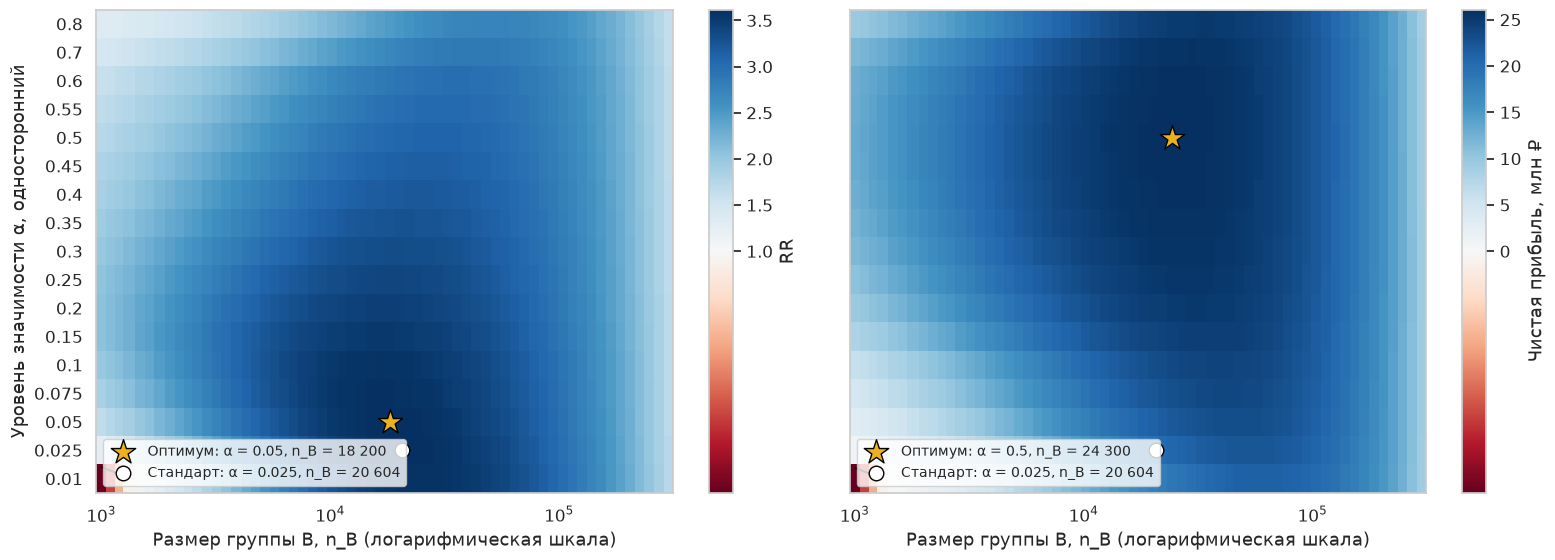

In [13]:
def plot_design_maps(grid: dict, marks: dict = None, title: str = None) -> None:
    """Рисует тепловые карты RR и прибыли на сетке alpha и n_B."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
    panels = [(axes[0], grid['rr'], 1, 'RR', 'rr'), (axes[1], grid['net'] / 1e6, 0, 'Чистая прибыль, млн ₽', 'net')]

    for ax, values, center, label, metric in panels:
        low, high = values.min(), values.max()
        if not low < center < high:
            low, high = min(low, center - 1e-6), max(high, center + 1e-6)
        mesh = ax.pcolormesh(n_grid, np.arange(alpha_grid.size), values, cmap='RdBu', shading='nearest',
                             norm=TwoSlopeNorm(vmin=low, vcenter=center, vmax=high))
        fig.colorbar(mesh, ax=ax, label=label)
        ax.contour(n_grid, np.arange(alpha_grid.size), values, levels=[center], colors='black', linewidths=1.5)

        best_alpha, best_n, *_ = best_design(grid, metric)
        ax.scatter(best_n, np.searchsorted(alpha_grid, best_alpha), marker='*', s=340, color='#EDB120',
                   edgecolor='black', zorder=4, label=f'Оптимум: α = {best_alpha}, n_B = {spaced(best_n)}')
        for name, (mark_alpha, mark_n) in (marks or {}).items():
            ax.scatter(mark_n, np.searchsorted(alpha_grid, mark_alpha), marker='o', s=110, color='white',
                       edgecolor='black', zorder=4, label=name)
        ax.set_xscale('log')
        ax.set_xlabel('Размер группы B, n_B (логарифмическая шкала)')
        ax.legend(loc='lower left', fontsize=10)
        ax.grid(False)

    axes[0].set_yticks(np.arange(alpha_grid.size), alpha_grid)
    axes[0].set_ylabel('Уровень значимости α, односторонний')
    if title:
        fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()


p, s = case.baseline_cr, case.share_b
n_standard = int(np.ceil((norm.ppf(0.975) + norm.ppf(0.8)) ** 2 * p * (1 - p) * (1 + s / (1 - s)) / 0.01 ** 2))
plot_design_maps(grid, {f'Стандарт: α = 0.025, n_B = {spaced(n_standard)}': (0.025, n_standard)})

Чёрная линия отделяет прибыльные дизайны (синие) от убыточных (красные). Маркер стандарта стоит на сетке, посчитанной против BE, поэтому его значение на карте соответствует гибриду; честный стандарт — в таблице ниже.

Сравним оптимумы со стандартом и с двумя решениями без теста. «Внедрить без теста» не платит за тест и не ждёт, но мониторинг и откат крупных провалов у него те же.

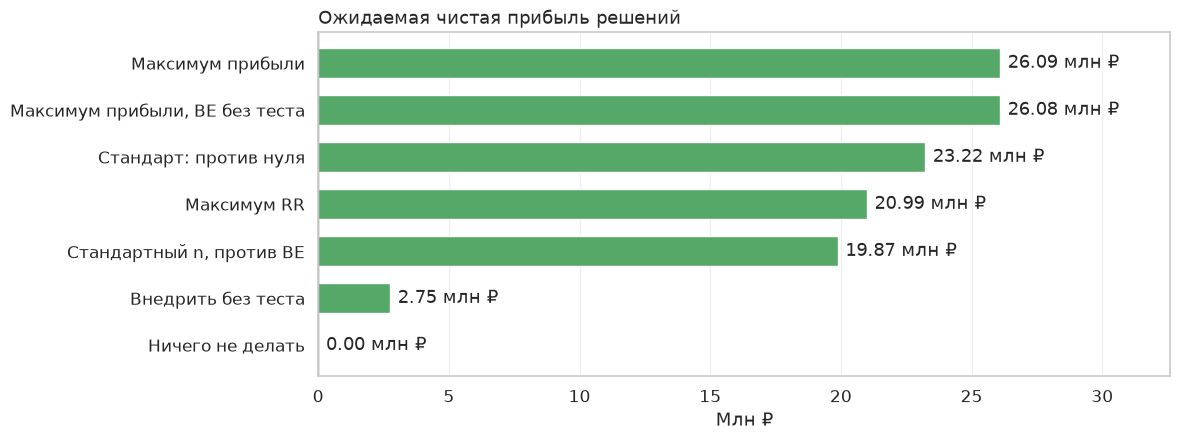

,RR,"Длительность, недель",α,"Чистая прибыль, млн ₽","Прибыль на неделю теста, млн ₽"
Внедрить без теста,NaN,NaN,NaN,2.748,NaN
Ничего не делать,NaN,NaN,NaN,0.000,NaN
Стандарт: против нуля,3.565,1.962,0.025,23.220,11.833
"Стандартный n, против BE",3.616,1.962,0.025,19.872,10.127
Максимум RR,3.617,1.733,0.050,20.988,12.108
Максимум прибыли,3.092,2.314,0.500,26.086,11.272
"Максимум прибыли, BE без теста",3.110,2.314,0.450,26.084,11.271


In [14]:
rr_alpha, rr_n, *_ = best_design(grid, 'rr')
net_alpha, net_n, *_ = best_design(grid, 'net')
sunk_grid = design_grid(case, break_even=case.break_even_sunk)
sunk_alpha, sunk_n, *_ = best_design(sunk_grid, 'net')

designs = {  # название: (alpha, n_B, порог решения)
    'Стандарт: против нуля': (0.025, n_standard, 0.0),
    'Стандартный n, против BE': (0.025, n_standard, case.break_even),
    'Максимум RR': (rr_alpha, rr_n, case.break_even),
    'Максимум прибыли': (net_alpha, net_n, case.break_even),
    'Максимум прибыли, BE без теста': (sunk_alpha, sunk_n, case.break_even_sunk),
}
options = {'Внедрить без теста': (ship_without_test(case, effect_grid, density), np.nan, np.nan, np.nan),
           'Ничего не делать': (0.0, np.nan, np.nan, np.nan)}
for name, (alpha, n_b, threshold) in designs.items():
    result = evaluate_design(case, effect_grid, density, n_b, alpha, threshold)
    options[name] = (float(result['net']), float(result['rr']), float(case.test_weeks(n_b)), alpha)

comparison = pd.DataFrame(options, index=['Чистая прибыль, ₽', 'RR', 'Длительность, недель', 'α']).T
comparison['Прибыль на неделю теста, ₽'] = comparison['Чистая прибыль, ₽'] / comparison['Длительность, недель']

ordered = comparison['Чистая прибыль, ₽'].sort_values()
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.barh(ordered.index, ordered.values / 1e6, color=[GREEN if value > 0 else RED for value in ordered.values], height=0.65)
for position, value in enumerate(ordered.values):
    ax.text(value / 1e6 + 0.3, position, f'{value / 1e6:.2f} млн ₽', va='center', ha='left')
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlim(0, ordered.max() / 1e6 * 1.25)
ax.set_title('Ожидаемая чистая прибыль решений', loc='left')
ax.set_xlabel('Млн ₽')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

shown = comparison.copy()
for column in ['Чистая прибыль, ₽', 'Прибыль на неделю теста, ₽']:
    shown[column.replace('₽', 'млн ₽')] = shown.pop(column) / 1e6
shown.round(3)

Что мы видим:

* **Оптимум лежит внутри сетки.** Лучший по прибыли дизайн длится 16 дней. Дальше потери от задержки внедрения перевешивают пользу от точности.
* **Критерии расходятся.** Максимум $RR$ даёт $\alpha = 0.05$ и 18.2 тыс. в группе B (12 дней), а максимум прибыли — $\alpha = 0.5$ и 24.3 тыс. (16 дней). Отношение поощряет экономию затрат, даже если абсолютная прибыль ниже: разница — 5.1 млн ₽.
* **Честный стандарт прибылен и близок к оптимуму:** 23.2 млн ₽ против 26.1 млн ₽. Он проигрывает только строгим порогом: длительность близкая, 14 дней против 16. Гибрид «стандартный $n$, но против BE» хуже обоих (19.9 млн ₽): строгий $\alpha$ поверх сдвинутого порога слишком осторожен.
* **Внедрение без теста почти бесполезно** (2.75 млн ₽): в плюс его выводит только откат крупных провалов. Варианты с небольшим вредом остаются на весь год. Именно отбор вариантов и создаёт ценность теста — ещё 23 млн ₽.

Высокий $\alpha$ здесь нельзя считать универсальным рецептом. Модель нейтральна к риску: она смотрит только на среднюю прибыль, а не на разброс исходов отдельного решения.

К тому же порог сравнивается с точкой безубыточности, а не с нулём. Поэтому $\alpha = 0.5$ означает правило «внедряем, если оценка выше 0.25 п.п.». Что это правило значит в терминах теста против нуля — в разделе «Вердикт для кейса».

### Sunk cost: затраты на тест в пороге

К моменту решения 3 млн ₽ на тест потрачены при любом исходе, поэтому рациональный порог их не учитывает: $\theta_{BE}$ падает с 0.351% до 0.309%.

Строка «Максимум прибыли, BE без теста» показывает, что от этого меняется: оптимальный $\alpha$ снижается с 0.5 до 0.45, а $n_B$ и прибыль остаются прежними. Решение зависит от границы внедрения $\delta_{BE} + z_{1-\alpha} SE$, и оптимизатор возвращает её на место через $\alpha$.

**Урок.** Включать sunk cost в порог — ошибка, но при $\alpha$, подобранном по деньгам, почти бесплатная. Дорого она обходится, когда $\alpha$ зафиксирован «по стандарту».

### RR зависит от разнесения статей

Проведём внедрение не как затрату, а как минус в выгодах: $Gain' = Gain_{RA} - C_{impl} \cdot P(\text{внедрение})$, $Cost' = Cost_{RA} - C_{impl} \cdot P(\text{внедрение})$. Прибыль та же, отношение — другое.

In [15]:
ship_share = np.trapezoid(grid['probability'] * density, effect_grid, axis=-1)
moved = case.implementation_cost * ship_share
rr_moved = (grid['expected_gain'] - moved) / (grid['expected_loss'] - moved)
row, column = np.unravel_index(np.argmax(rr_moved), rr_moved.shape)
print(f"RR как раньше: максимум {grid['rr'].max():.2f} при α = {rr_alpha}, n_B = {spaced(rr_n)}")
print(f"RR с внедрением в выгодах: максимум {rr_moved.max():.2f} при α = {alpha_grid[row]}, n_B = {spaced(n_grid[column])}")
print(f"Прибыль в обоих случаях одинакова: {np.allclose(grid['net'], (grid['expected_gain'] - moved) - (grid['expected_loss'] - moved))}")

RR как раньше: максимум 3.62 при α = 0.05, n_B = 18 200
RR с внедрением в выгодах: максимум 4.63 при α = 0.075, n_B = 20 000
Прибыль в обоих случаях одинакова: True


Оптимум RR переехал, хотя деньги не изменились. Отсюда поправка к популярному совету «если тестов много, а ресурсов мало — смотрите на RR». В портфеле дефицитен обычно трафик, поэтому сравнивать дизайны стоит по **прибыли на единицу дефицитного ресурса** — на неделю теста (последний столбец таблицы выше): 12.1 млн ₽ у максимума RR, 11.8 у стандарта, 11.3 у максимума прибыли. Короткий тест освобождает трафик для следующей идеи. Оговорка: этот критерий честен, пока в очереди есть сопоставимые идеи. Если довести его до предела, он будет тянуть к сколь угодно коротким тестам.

**Вопрос.** Почему максимум RR выбирает более строгий $\alpha$ и более короткий тест, чем максимум прибыли? Какой критерий брать?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

RR — отношение. Его можно поднять, урезая затраты быстрее, чем выгоды: строгий $\alpha$ реже платит 10 млн ₽ за внедрение, короткий тест меньше рискует во время теста. Прибыль при этом падает на 5 млн ₽.

Для одного решения берём прибыль. Если трафик дефицитен и идей в очереди много — прибыль на неделю теста (абзац выше). RR сам по себе не годится: он меняется от того, как разнести статьи.

</details>

**Попробуйте сами.** Поставьте `SHOW_SLIDERS = True` (нужен `ipywidgets`) и посмотрите, как оптимум реагирует на бизнес-параметры: сдвиньте среднее ожиданий в минус, сократите горизонт или поднимите стоимость внедрения. Без слайдеров ячейка рисует пример с горизонтом 3 месяца.

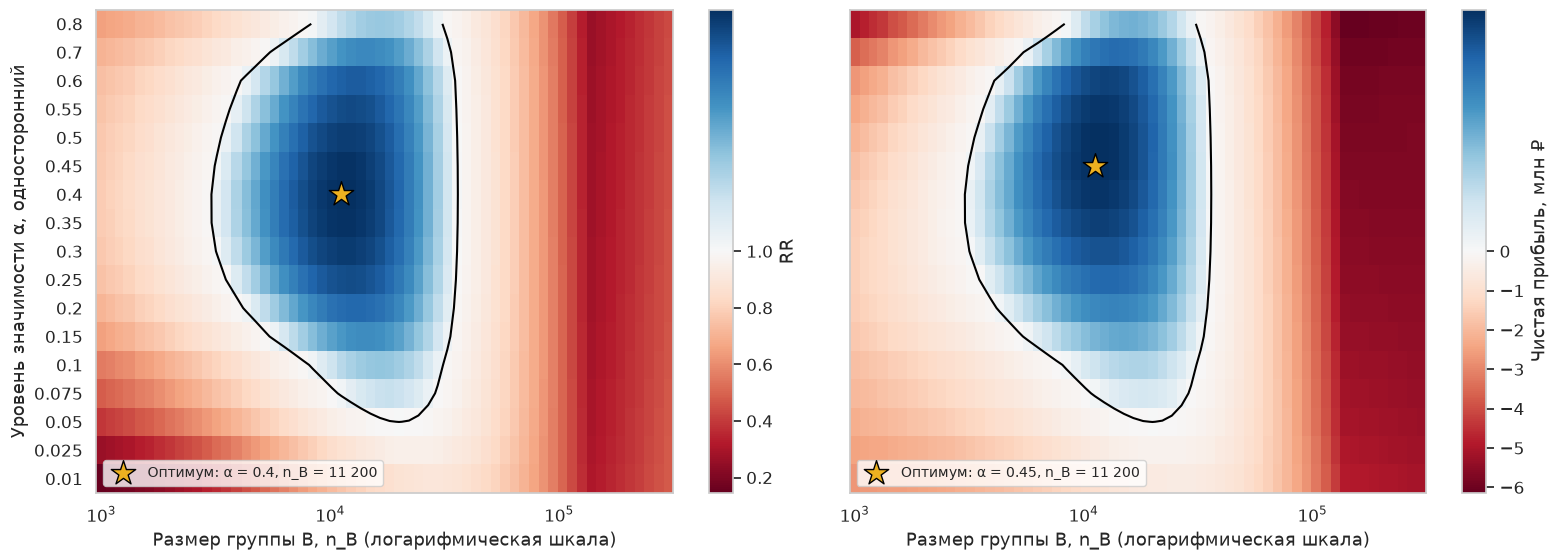

In [16]:
def optimum_demo(prior_mean: float = 0.0, prior_std: float = 1.5, horizon_months: int = 12, implementation: int = 10) -> None:
    """Пересчитывает карты дизайнов для других ожиданий (в %) и бизнес-параметров (месяцы, млн ₽)."""
    custom_case = replace(case, horizon_months=horizon_months, implementation_cost=implementation * 1e6)
    plot_design_maps(design_grid(custom_case, prior_density(prior_mean / 100, prior_std / 100)))


SHOW_SLIDERS = False

if SHOW_SLIDERS and interact is not None:
    interact(optimum_demo,
             prior_mean=FloatSlider(value=0, min=-1, max=1, step=0.25, description='μ, %'),
             prior_std=FloatSlider(value=1.5, min=0.5, max=3, step=0.25, description='σ, %'),
             horizon_months=IntSlider(value=12, min=3, max=36, step=3, description='Горизонт'),
             implementation=IntSlider(value=10, min=0, max=60, step=5, description='Внедр., млн'));
else:
    optimum_demo(horizon_months=3)

Как меняется оптимум при других ожиданиях и параметрах (та же сетка эффектов, поэтому базовая строка совпадает с таблицей выше):

In [17]:
scenarios = {
    'Базовый': ({}, 0.0, 0.015),
    'Ждём ухудшение: μ = −0.5%': ({}, -0.005, 0.015),
    'Ждём улучшение: μ = +0.5%': ({}, 0.005, 0.015),
    'Узкие ожидания: σ = 0.75%': ({}, 0.0, 0.0075),
    'Широкие ожидания: σ = 3%': ({}, 0.0, 0.03),
    'Горизонт 3 месяца': ({'horizon_months': 3}, 0.0, 0.015),
    'Горизонт 36 месяцев': ({'horizon_months': 36}, 0.0, 0.015),
    'Дорогое внедрение: 40 млн ₽': ({'implementation_cost': 40_000_000}, 0.0, 0.015),
    'Нет мониторинга и отката': ({'rollback_threshold': -1.0}, 0.0, 0.015),
}
rows = []
for name, (changes, mu, sigma) in scenarios.items():
    custom = replace(case, **changes)
    weights = prior_density(mu, sigma)
    best_alpha, best_n, best_rr, best_net = best_design(design_grid(custom, weights), 'net')
    no_test = ship_without_test(custom, effect_grid, weights)
    rows.append({'Сценарий': name, 'BE, %': round(custom.break_even * 100, 3), 'α': best_alpha, 'n_B': best_n,
                 'Дней': round(custom.test_weeks(best_n) * 7, 1),
                 'Прибыль теста, млн ₽': round(best_net / 1e6, 2), 'Без теста, млн ₽': round(no_test / 1e6, 2),
                 'Вердикт': 'тестируем' if best_net > max(0, no_test) else 'не тестируем'})
sensitivity = pd.DataFrame(rows).set_index('Сценарий')
assert abs(sensitivity.loc['Базовый', 'Прибыль теста, млн ₽'] - comparison.loc['Максимум прибыли', 'Чистая прибыль, ₽'] / 1e6) < 0.01
sensitivity

,"BE, %",α,n_B,Дней,"Прибыль теста, млн ₽","Без теста, млн ₽",Вердикт
Сценарий,,,,,,,
Базовый,0.351,0.50,24300,16.2,26.09,2.75,тестируем
Ждём ухудшение: μ = −0.5%,0.351,0.45,26800,17.9,13.96,-16.38,тестируем
Ждём улучшение: μ = +0.5%,0.351,0.55,22100,14.7,42.82,27.30,тестируем
Узкие ожидания: σ = 0.75%,0.351,0.45,52600,35.1,6.22,-19.24,тестируем
Широкие ожидания: σ = 3%,0.351,0.50,12300,8.2,67.98,49.25,тестируем
Горизонт 3 месяца,0.898,0.45,11200,7.5,0.93,-9.00,тестируем
Горизонт 36 месяцев,0.229,0.50,43400,28.9,97.04,34.08,тестируем
Дорогое внедрение: 40 млн ₽,0.772,0.45,24300,16.2,15.45,-27.25,тестируем
Нет мониторинга и отката,0.351,0.50,24300,16.2,26.09,-22.00,тестируем


* **Ожидания сдвигают порог.** Ждём плохого — $\alpha$ строже (0.45), ждём хорошего — мягче (0.55). Прибыль меняется втрое: от 14 до 43 млн ₽.
* **Узкие ожидания требуют большей выборки:** эффекты мелкие, тест вдвое длиннее (35 дней), прибыль падает в 4 раза, а раскатка без теста становится убыточной (−19 млн ₽).
* **Широкие ожидания** — наоборот: хватает 8 дней, ставка выше.
* **Короткий горизонт** (3 месяца): внедрение окупать почти некогда, BE вырастает с 0.35% до 0.9%. Тест сжимается до недели, его прибыль — до 0.9 млн ₽, а раскатка без теста даёт −9 млн ₽. Вердикт «тестируем» держится на волоске.
* **Длинный горизонт разрешает длинный тест:** при 36 месяцах оптимум — 29 дней, потому что задержка стоит относительно дешевле.
* **Дорогое внедрение** поднимает BE до 0.77% и делает раскатку без теста глубоко убыточной (−27 млн ₽). Длительность теста та же (16 дней), $\alpha$ снижается с 0.5 до 0.45, прибыль падает с 26.1 до 15.5 млн ₽.
* **Мониторинг и откат не меняют дизайн теста:** откат нужен только варианту хуже −1.5%, а тест с оптимальным порогом пропускает такой вариант с вероятностью меньше 0.005%. Зато без них раскатка без теста уходит в −22 млн ₽. Откат страхует тех, кто не тестирует.

Оптимальный $\alpha$ здесь всюду около 0.5, но это свойство кейса: цена ошибки мала по сравнению с выручкой за год, а модель нейтральна к риску. Даже при внедрении за 40 млн ₽ строже становится не $\alpha$, а сам порог — BE вырос с 0.35% до 0.77%. $\alpha$ уходит заметно ниже 0.5, только когда в модель входят неприятие риска или необратимость, которых здесь нет. Поэтому расчёт делается под конкретный тест, а в дизайн-док (встреча 2) записываем не только числа, но и допущения.

**Вопрос.** Какой из параметров вы бы проверили первым, прежде чем доверять оптимуму, и почему?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Ожидания ($\mu$ и $\sigma$) и горизонт: они двигают и длительность, и прибыль сильнее всего, а оцениваются хуже всего.

* $\sigma$ берётся из суждения и грубой истории тестов (выше видно, как выброс утраивает оценку).
* Горизонт 12 месяцев предполагает, что эффект держится весь год; эффект новизны и изменения продукта сокращают его на практике.

Затраты на тест и внедрение обычно известны точнее, и оптимум к ним устойчивее.

</details>

## Проведение тестирования при α = 0.5?

### Провокационный вопрос

Георгиев задаёт провокационный вопрос: **что если установить уровень значимости $\alpha = 0.5$?** Для простоты сравним с нулём, то есть возьмём $\theta_{BE} = 0$.

На первый взгляд это абсурдно. Кажется, что такой тест равносилен подбрасыванию монетки. Но это неверное прочтение $\alpha$:

* $\alpha$ — это вероятность внедрения **при нулевом эффекте**, а не вероятность ошибки в любом решении. Доля ошибочных внедрений зависит ещё и от распределения реальных эффектов.
* Монетка внедряла бы вариант с вероятностью 50% **независимо от эффекта**, а тест с односторонним $\alpha = 0.5$ внедряет вариант, если его оценка эффекта положительна, поэтому вероятность внедрения растёт с эффектом.

### Асимметрия вероятности внедрения

Асимметрия возникает потому, что **решение одностороннее**: мы внедряем вариант, только если его оценка достаточно высока. Ухудшение значимым образом не приводит к внедрению, и поэтому хорошие и плохие варианты имеют разные шансы.

В основе теста лежит сравнение конверсий контрольной ($p_A$) и тестовой ($p_B$) групп: $z = (\hat{p}_B - \hat{p}_A) / SE$, где $SE$ — та же стандартная ошибка, что в разделе «Вероятность внедрения».

Если эффекта нет, то $z$ распределена стандартно нормально. Если эффект есть, распределение сдвигается на **параметр нецентральности** со знаком:

$$
\text{NCP} = \frac{p_B - p_A}{SE}
$$

Мы внедряем вариант, если $z > z_{1-\alpha}$. Вероятность этого равна:

$$
P(\text{внедрение}) = 1 - \Phi(z_{1-\alpha} - \text{NCP})
$$

Рассмотрим два случая:

* **Положительный эффект ($p_B > p_A$):** $\text{NCP} > 0$, и с ростом эффекта вероятность стремится к 1. Это мощность.
* **Отрицательный эффект ($p_B < p_A$):** $\text{NCP} < 0$, и с ростом ухудшения вероятность стремится к 0. Это уже не мощность, а вероятность внедрить плохой вариант.

Скорость этих переходов определяется величиной $\text{NCP}$, то есть **размером выборки**. Анимация (на условном примере с равными группами) показывает, как при росте выборки обе кривые становятся круче.

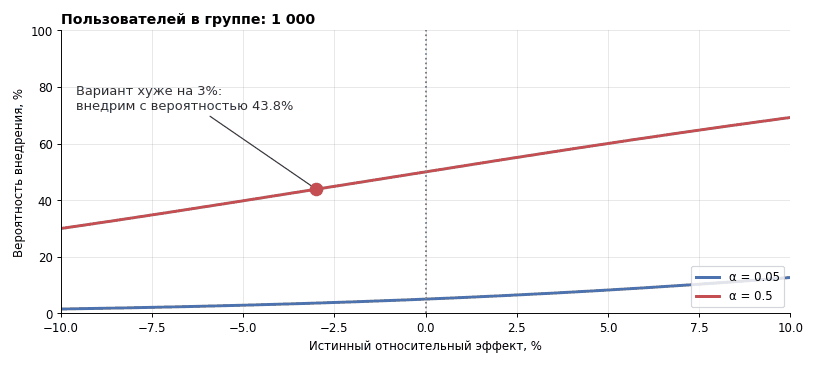

In [18]:
effects_table = np.array([-0.02, -0.01, 0.0, 0.01, 0.02])
table = pd.DataFrame(index=[f'{value:+.0%}' for value in effects_table])
table.index.name = 'Истинный эффект'
for n_b in [2_000, 21_000]:
    for alpha_val in [0.025, 0.5]:
        table[f'n_B = {spaced(n_b)}, α = {alpha_val}'] = implementation_probability(
            case.baseline_cr, effects_table, 0.0, n_b, alpha_val, case.share_b).round(3)

table

,"n_B = 2 000, α = 0.025","n_B = 2 000, α = 0.5","n_B = 21 000, α = 0.025","n_B = 21 000, α = 0.5"
Истинный эффект,,,,
-2%,0.001,0.113,0.000,0.000
-1%,0.005,0.272,0.000,0.024
+0%,0.025,0.500,0.025,0.500
+1%,0.089,0.731,0.512,0.977
+2%,0.234,0.892,0.980,1.000


Таблица показывает, что всё зависит от выборки. При $n_B = 2000$ тест слабый: вариант на 1% хуже контроля будет внедрён при $\alpha = 0.5$ с вероятностью 27%. При $n_B = 21000$ эта вероятность падает до 2.4%. При нулевом эффекте вероятность внедрения равна $\alpha$ при любом $n$.

Чтобы оценить риск целиком, посчитаем для априорного распределения, какая доля внедрений окажется ошибочной и какой средний эффект получит продукт за одно решение. Сравниваем монетку с тестами при $\theta_{BE} = 0$ и без учёта затрат.

In [19]:
def rollout_quality(n_b: int, alpha: float) -> pd.Series:
    """Считает долю внедрений, долю ошибочных внедрений и средний эффект для априорного распределения."""
    if alpha is None:  # монетка
        probability = np.full_like(effect_grid, 0.5)
    else:
        probability = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_b, alpha, case.share_b)
    p_ship = np.trapezoid(probability * density, effect_grid)
    p_bad_ship = np.trapezoid(probability * density * (effect_grid < 0), effect_grid)
    return pd.Series({
        'Доля внедрений': p_ship,
        'Доля плохих среди внедрённых': p_bad_ship / p_ship,
        'Средний эффект на решение, %': np.trapezoid(effect_grid * probability * density, effect_grid) * 100,
    })


pd.DataFrame({
    'Монетка': rollout_quality(0, None),
    'n_B = 2 000, α = 0.025': rollout_quality(2_000, 0.025),
    'n_B = 2 000, α = 0.5': rollout_quality(2_000, 0.5),
    'n_B = 21 000, α = 0.025': rollout_quality(21_000, 0.025),
    'n_B = 21 000, α = 0.5': rollout_quality(21_000, 0.5),
}).T.round(3)

,Доля внедрений,Доля плохих среди внедрённых,"Средний эффект на решение, %"
Монетка,0.500,0.499,0.000
"n_B = 2 000, α = 0.025",0.075,0.049,0.145
"n_B = 2 000, α = 0.5",0.501,0.263,0.404
"n_B = 21 000, α = 0.025",0.267,0.005,0.468
"n_B = 21 000, α = 0.5",0.500,0.102,0.567


* **Монетка** внедряет половину вариантов, половина внедрённых плоха, а средний эффект равен нулю.
* **Тест с $\alpha = 0.5$** внедряет столько же, но плохих среди внедрённых заметно меньше: 26% при $n_B = 2000$ и 10% при $n_B = 21000$. Средний эффект положителен.
* **Строгий порог при той же выборке** даёт меньше плохих внедрений (5% и 0.5%), но пропускает хорошие варианты, и средний эффект оказывается ниже.

Итак, $\alpha = 0.5$ — не монетка, но и не бесплатный подарок: среди внедрённых останется заметная доля плохих вариантов, а защищает от них только выборка. Георгиев тоже подчёркивает, что этот пример не означает, будто тестировать на 50% лучше, чем на 95%: оптимальный порог зависит от всех параметров.

**Попробуйте сами.** Поставьте `SHOW_SLIDERS = True` и подвигайте $\alpha$ и $n_B$. Цифры над графиком показывают вероятность внедрить вариант, который на 1% хуже контроля, и вариант, который на 1% лучше.

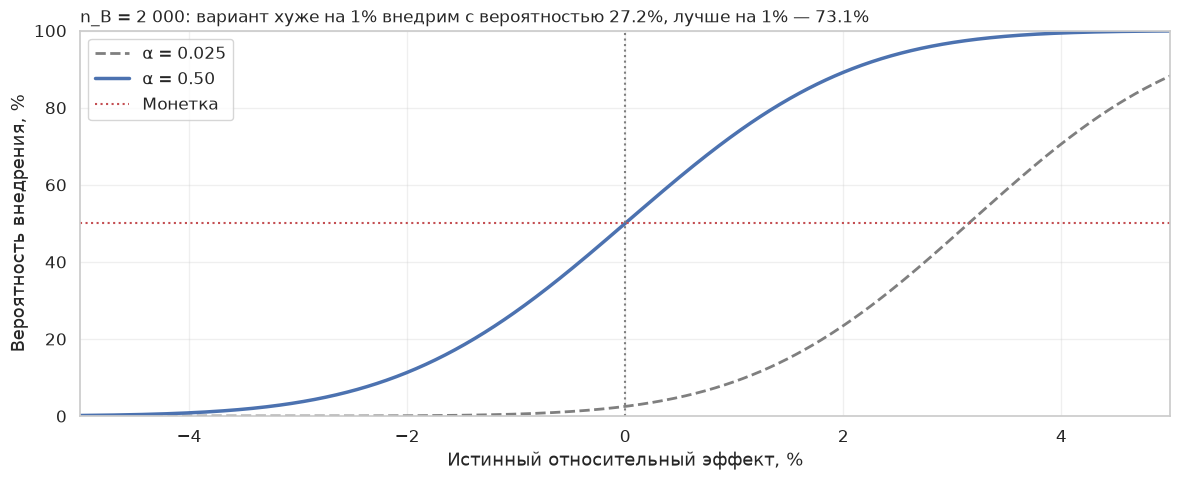

In [20]:
def asymmetry_demo(alpha: float = 0.5, n_thousands: int = 2) -> None:
    """Сравнивает вероятность внедрения при выбранных alpha и n_B с дизайном alpha = 0.025, решение против нуля."""
    n_b = n_thousands * 1_000
    chosen = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_b, alpha, case.share_b)
    reference = implementation_probability(case.baseline_cr, effect_grid, 0.0, n_b, 0.025, case.share_b)
    worse, better = implementation_probability(case.baseline_cr, np.array([-0.01, 0.01]), 0.0, n_b, alpha, case.share_b)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(effect_grid * 100, reference * 100, color=GRAY, linewidth=2, linestyle='--', label='α = 0.025')
    ax.plot(effect_grid * 100, chosen * 100, color=BLUE, linewidth=2.5, label=f'α = {alpha:.2f}')
    ax.axhline(50, color=RED, linewidth=1.5, linestyle=':', label='Монетка')
    ax.axvline(0, color=GRAY, linestyle=':', linewidth=1.5)
    ax.set_title(f'n_B = {spaced(n_b)}: вариант хуже на 1% внедрим с вероятностью {worse:.1%}, лучше на 1% — {better:.1%}',
                 loc='left', fontsize=12)
    ax.set_xlabel('Истинный относительный эффект, %')
    ax.set_ylabel('Вероятность внедрения, %')
    ax.set_ylim(0, 100)
    ax.set_xlim(-5, 5)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


if SHOW_SLIDERS and interact is not None:
    interact(asymmetry_demo,
             alpha=FloatSlider(value=0.5, min=0.01, max=0.8, step=0.01, description='α'),
             n_thousands=IntSlider(value=2, min=1, max=100, step=1, description='n_B, тыс'));
else:
    asymmetry_demo()

**Вопрос.** Коллега из другой команды предлагает: «раз α = 0.5 выгоднее, давайте во всех тестах решать против нуля с α = 0.5». Что ответить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Это перенос числа без условий, при которых оно получено.

1. **Порог.** Наш $\alpha = 0.5$ стоит против точки безубыточности, а не против нуля. Против нуля $\alpha = 0.5$ внедряет любой вариант с положительной оценкой, в том числе те, что не окупают внедрение.
2. **Цена ошибки.** У нас ошибка дешёвая и обратимая: откат за 5 млн ₽ при выручке 7 млрд ₽ в год. Для дорогих и необратимых решений оптимальный порог строже.
3. **Выборка.** От плохих внедрений при высоком $\alpha$ защищает только выборка: при $n_B = 2000$ вредных среди внедрённых 26%.
4. **Нейтральность к риску.** Модель смотрит на среднюю прибыль. Если команде важен разброс исходов, $\alpha$ нужно снижать.

Правильный ответ коллеге — посчитать свою модель, а не брать наше число.

</details>

## Вердикт для кейса

Соберём ответ владельцу продукта. Оптимальный $n_B = 24300$ — это 16.2 дня, но тест нельзя остановить посреди недели: поведение в будни и выходные различается. Сравним две и три недели, для каждой подберём лучший $\alpha$ и сопоставим с альтернативами без теста.

In [21]:
optimum_days = net_n / (case.share_b * case.daily_users)
candidates = []
for weeks in sorted({max(1, int(np.floor(optimum_days / 7))), int(np.ceil(optimum_days / 7))}):
    n_b = int(weeks * 7 * case.share_b * case.daily_users)
    result = evaluate_design(case, effect_grid, density, n_b, alpha_grid[:, None])
    i = int(np.argmax(result['net']))
    candidates.append({'weeks': weeks, 'alpha': float(alpha_grid[i]), 'n_b': n_b, 'net': float(result['net'][i])})
    print(f"{weeks} нед.: n_B = {spaced(n_b)}, лучший α = {alpha_grid[i]}, прибыль {result['net'][i] / 1e6:.2f} млн ₽")

chosen = max(candidates, key=lambda row: row['net'])
no_test = ship_without_test(case, effect_grid, density)
VERDICT = {
    'alpha': chosen['alpha'],
    'break_even_pp': float(round(case.break_even * case.baseline_cr * 100, 3)),   # H0: p_B − p_A ≤ break_even_pp п.п., α одностороннее
    'n_b': chosen['n_b'],
    'n_total': int(round(chosen['n_b'] / case.share_b)),
    'days': chosen['weeks'] * 7,
    'decision': 'тестируем' if chosen['net'] > max(0.0, no_test) else 'не тестируем',
}
z = norm.ppf(1 - VERDICT['alpha'])
se_pp = 100 * np.sqrt(case.baseline_cr * (1 - case.baseline_cr) * (1 / (VERDICT['n_total'] - VERDICT['n_b']) + 1 / VERDICT['n_b']))
boundary = VERDICT['break_even_pp'] + z * se_pp
if abs(z) < 1e-12:   # α = 0.5 ⇒ z = 0: порог внедрения равен самой точке безубыточности
    print(f"Правило: внедряем, если p̂_B − p̂_A > {boundary:.2f} п.п. (α = 0.5 ⇒ z = 0, порог равен BE; SE ≈ {se_pp:.2f} п.п.)")
else:
    print(f"Правило: внедряем, если p̂_B − p̂_A > {VERDICT['break_even_pp']:.2f} п.п. + {z:.2f} · SE = {boundary:.2f} п.п. (SE ≈ {se_pp:.2f} п.п.)")
print(f"В терминах теста против нуля это одностороннее α ≈ {norm.sf(boundary / se_pp):.2f}; мощность 80% — для разницы ≈ {boundary + norm.ppf(0.8) * se_pp:.2f} п.п.")
VERDICT

2 нед.: n_B = 21 000, лучший α = 0.5, прибыль 26.03 млн ₽
3 нед.: n_B = 31 500, лучший α = 0.5, прибыль 26.01 млн ₽
Правило: внедряем, если p̂_B − p̂_A > 0.25 п.п. (α = 0.5 ⇒ z = 0, порог равен BE; SE ≈ 0.35 п.п.)
В терминах теста против нуля это одностороннее α ≈ 0.24; мощность 80% — для разницы ≈ 0.54 п.п.


{'alpha': 0.5,
 'break_even_pp': 0.246,
 'n_b': 21000,
 'n_total': 105000,
 'days': 14,
 'decision': 'тестируем'}

**Вердикт: тестируем две недели**, $n_B = 21000$ (всего 105 тыс. пользователей), решение — одностороннее $\alpha = 0.5$ против точки безубыточности, то есть «внедряем, если конверсия B выше A хотя бы на 0.25 п.п.». Против нуля это одностороннее $\alpha \approx 0.24.$ Ожидаемая прибыль — 26.0 млн ₽ против 2.75 млн ₽ без теста. Две недели проигрывают трём лишь десятки тысяч рублей: плато прибыли широкое, и округление до недель почти ничего не стоит.

Вердикт — вход встречи 2: по нему считаем MDE, проверяем длительность и пишем дизайн-док. Совпадение с датасетом не случайно: `checkout_ab.csv` — это ровно 14 дней теста по такому плану. Во встречу 2 передаём не только $\alpha$, но и порог: $\alpha = 0.5$ без `break_even_pp` теряет смысл.

**Вопрос.** Вердикт — $\alpha = 0.5$ против точки безубыточности. Как сформулировать правило решения владельцу продукта так, чтобы он не услышал «подбрасываем монетку»?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

«Через две недели внедряем новый чекаут, если его конверсия в тесте выше старой хотя бы на 0.25 п.п. Это точка, где он окупает тест, внедрение и год поддержки».

Одностороннее $\alpha = 0.5$ против BE и есть правило «оценка выше порога». Вероятность внедрить вариант растёт с его эффектом, а не равна 50%.

Цену правила тоже называем числами (их даёт `implementation_probability`):

* вариант на 1% хуже контроля внедрится с вероятностью 0.4%;
* вариант без эффекта — с вероятностью 24%;
* вариант на 1% лучше — с вероятностью 90%.

Крупные провалы, если всё же проскочат, ловит мониторинг после раскатки.

</details>

**Вопрос.** Что изменится в вердикте, если откатить новый чекаут нельзя: старый уже удалён из кода?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Дизайн теста — почти ничего: строка «Нет мониторинга и отката» в таблице сценариев совпадает с базовой. Тест с порогом на уровне BE и так почти не пропускает вариант хуже −1.5%.

Меняется альтернатива: раскатка без теста падает с +2.75 до −22 млн ₽. Значит, тест становится ещё нужнее, а вердикт «тестируем» — ещё надёжнее.

Отдельно стоит спросить, почему старый чекаут удаляют до решения: дешёвый откат — это страховка, которая стоит дешевле теста.

</details>

## Ограничения модели

### Кратко

1. **Упрощённое распределение ожиданий.** На практике оно может быть сложнее и асимметричнее, с тяжёлыми хвостами.
2. **Постоянный эффект.** Эффект может затухать со временем (novelty effect).
3. **Долгосрочные эффекты.** Некоторые изменения влияют на LTV, бренд и лояльность.
4. **Альтернативные издержки.** Время и ресурсы на тест можно потратить иначе.
5. **Проблема референтного класса.** Выбор априорного распределения субъективен.
6. **Упрощённый мониторинг.** Считаем, что за 4 недели после внедрения падение ниже −1.5% видно точно, а меньшее — не видно совсем. В реальности порог размытый, а оценка после раскатки без контроля шумная. Это упрощение, а не пессимизм: оно занижает пользу отката для мелкого вреда и завышает для крупного.
7. **Фиксированные затраты в пороге.** К моменту решения затраты на тест уже понесены. В основной модели мы следуем исходной постановке, где они включены; без них оптимальный $\alpha$ снижается с 0.5 до 0.45, а прибыль не меняется (раздел про sunk cost).

Тем не менее подход даёт практический фреймворк для выбора дизайна с учётом бизнес-контекста.

### Развёрнуто

Расчёт отношения выгоды к риску точен настолько, насколько точны исходные данные. Если распределение ожиданий искажено, затраты недооценены или выгоды преувеличены, «оптимальный» дизайн на самом деле оптимальным не будет. То же верно для ошибки в горизонте использования. Существует «достаточно хороший» уровень оценки, который уравновешивает сложность получения точных оценок и их пользу.

**Долгосрочные эффекты.** Они мешают A/B-тестам вообще: и затраты, и выгоды трудно измерить в краткосрочном эксперименте при изменчивости продукта, технологий, ожиданий пользователей и рынка. Модель предполагает, что эффект примерно одинаков весь горизонт, но эффекты новизны исчезают, а внешние обстоятельства меняются.

**Постоянные изменения пользовательского опыта.** Продукты с большим числом тестов могут страдать от самого факта частых изменений независимо от результатов. Если главная страница и корзина меняются каждый месяц, это может негативно влиять на пользователей, особенно на сервисах с частыми возвращениями. Этот эффект мало изучен, но о нём стоит помнить.

**Альтернативная стоимость.** Деньги и время, потраченные на тест, можно вложить во что-то другое. Некоторым компаниям выгоднее отказаться от теста и пойти на больший риск. A/B-тест — средство достижения цели, а не сама цель.

Ответить на вопрос об альтернативной стоимости помогает сравнение с решением без теста, которое мы сделали выше: оно показывает, сколько на самом деле добавляет тестирование.

## Заключение

* Стандартные $\alpha = 0.05$ и мощность 80% — это соглашение, а не оптимум для бизнеса.
* Дизайн можно подбирать под деньги: нужны затраты, выручка, горизонт и распределение ожидаемых эффектов.
* Цель нужно выбирать явно: максимум отношения выгоды к риску и максимум прибыли дают разные дизайны.
* Модель обязана учитывать цену времени, иначе «оптимальная» выборка будет бесконечно расти, и согласованный откат: он обрывает и потери, и выгоду.
* $RR$ зависит от разнесения статей, прибыль — нет; для портфеля сравнивайте прибыль на неделю трафика.
* Высокое $\alpha$ не равно монетке, но и не безопасно само по себе: защита от плохих вариантов зависит от размера выборки.
* Чем дороже и необратимее ошибка, тем строже оптимальный порог, поэтому результат нужно проверять на чувствительность к ожиданиям и затратам.